# Step 16b — TabPFN and TabICL on the bundles of three other papers

The same four variants as step 8 (which used the variables of Dang et al. 2024), now on the cohorts and variables of Chen et al. 2025 (adults living alone), Jin et al. 2025 (serum PFAS) and ShangGuan et al. 2026 (physically inactive adults). The bundles and what is in them are described in `step16_export_bundles.ipynb`.

**Standalone:** the Run part needs only this notebook and the folder `step16_bundles/`, so it can run on any GPU machine. Packages: python ≥ 3.10, numpy, pandas, scikit-learn, torch, `tabpfn==9.2.0`, `tabicl==2.2.0` (`modeling/requirements-foundation.txt`). TabPFN weights need the free non-commercial license: accept it once at https://ux.priorlabs.ai and set `TABPFN_TOKEN`.

```bash
export TABPFN_TOKEN=...
export STEP16_BUNDLES=$PWD/step16_bundles STEP16_OUT=$PWD/step16_out    # absolute paths
NHANES_RUN=1 NHANES_QUICK=1 jupyter execute modeling/step16_foundation_models.ipynb      # a few minutes, checks the setup
NHANES_RUN=1 jupyter execute --inplace modeling/step16_foundation_models.ipynb           # everything
```

**Variants** (package defaults, no tuning):

| variant | model | target | score |
|---|---|---|---|
| tabpfn_clf | TabPFNClassifier | 0/1 label (PHQ-9 ≥ 10) | P(depressed) |
| tabpfn_reg | TabPFNRegressor | PHQ-9 total | predicted total |
| tabicl_clf | TabICLClassifier | 0/1 label | P(depressed) |
| tabicl_reg | TabICLRegressor | PHQ-9 total | predicted total |

The regressors are scored against the same 0/1 label: AUROC only needs a ranking, and the predicted total is one.

**Tasks**, per bundle and feature set (`all` = every candidate variable; `paper` = the variables the paper selected, for Chen and ShangGuan):
- `cv0`–`cv9`: train on 9 folds, predict the 10th.
- `paper`: train on the paper's training part, predict its test part (and the validation sets of ShangGuan).

In total 5 feature sets × 11 tasks × 4 variants = 220 fits, on at most 9,000 training rows.

Categorical variables are passed as pandas `category` columns, continuous ones as floats with missing values left as NaN (only the ShangGuan bundle has any).

Each result is written to `OUT/<bundle>/<feature set>/<variant>/<task>.csv` (SEQN, part, fold, depression, phq9, score) as soon as it finishes, and finished ones are skipped on a rerun. `QUICK`: the Chen bundle, feature set `paper`, task `cv0` only, written to `OUT/quick/`.

The Results part reads `OUT` and the conventional baselines stored in the bundles (logistic regression, random forest, XGBoost, CatBoost on the same tasks), and compares them fold by fold.

In [1]:
import json
import os
import platform
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

RUN = False      # True: fit the models (GPU machine)
QUICK = False    # with RUN: one small task, to check the setup
MODELS = ["tabpfn_clf", "tabpfn_reg", "tabicl_clf", "tabicl_reg"]
if os.environ.get("STEP16_MODELS"):  # e.g. STEP16_MODELS=tabpfn_clf,tabpfn_reg runs (and shows) only TabPFN
    MODELS = os.environ["STEP16_MODELS"].split(",")
DEVICE = None    # None: cuda if available, else cpu
SEED = 42
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"

# Inside this repository the bundles and outputs default to $NHANES_WORK/modeling; standalone, set the two variables.
try:
    import sys
    _cwd = Path.cwd().resolve()
    sys.path.insert(0, str(next(p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file())))
    from nhanes.paths import RESULTS
except StopIteration:
    RESULTS = None
BUNDLES = Path(os.environ.get("STEP16_BUNDLES", RESULTS / "step16_bundles" if RESULTS else "step16_bundles"))
OUT = Path(os.environ.get("STEP16_OUT", RESULTS / "step16_out" if RESULTS else "step16_out"))
NAMES = {"chen2025_living_alone": "Chen 2025 (living alone)", "jin2025_pfas": "Jin 2025 (PFAS)",
         "shangguan2026_inactive": "ShangGuan 2026 (inactive)"}


def load(bundle):
    d = pd.read_csv(BUNDLES / bundle / "data.csv.gz")
    cols = json.loads((BUNDLES / bundle / "columns.json").read_text())
    return d, cols


def tasks(d):
    """(name, training rows, rows to predict); the same as for the baselines in step16_export_bundles."""
    out = [(f"cv{k}", np.flatnonzero((d.fold >= 0) & (d.fold != k)), np.flatnonzero(d.fold == k)) for k in range(10)]
    return out + [("paper", np.flatnonzero(d.part == "train"), np.flatnonzero(d.part != "train"))]

## Run

In [2]:
if RUN:
    import torch
    from sklearn.metrics import roc_auc_score

    def frame(d, feats, cols):
        X = d[feats].copy()
        for c in feats:
            if c in cols["categorical"]:
                X[c] = X[c].astype("Int64").astype("category")
            else:
                X[c] = X[c].astype(float)
        return X

    def make(model, device):
        if model.startswith("tabpfn"):
            from tabpfn import TabPFNClassifier, TabPFNRegressor
            cls = TabPFNClassifier if model.endswith("clf") else TabPFNRegressor
            return cls(device=device, random_state=SEED)
        from tabicl import TabICLClassifier, TabICLRegressor
        cls = TabICLClassifier if model.endswith("clf") else TabICLRegressor
        return cls(device=device, random_state=SEED)

    def score(m, model, X, chunk):
        """Predict in chunks of `chunk` rows (0 = all at once)."""
        parts = [X] if not chunk else [X.iloc[i:i + chunk] for i in range(0, len(X), chunk)]
        if model.endswith("clf"):
            return np.concatenate([m.predict_proba(p)[:, list(m.classes_).index(1)] for p in parts])
        return np.concatenate([np.asarray(m.predict(p), dtype=float) for p in parts])

    def run_one(model, d, X, tr, te, device):
        y = d.depression if model.endswith("clf") else d.phq9.astype(float)
        m = make(model, device).fit(X.iloc[tr], y.iloc[tr])
        for chunk in (0, 1000, 250):
            try:
                return score(m, model, X.iloc[te], chunk)
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                print(f"  out of GPU memory with chunk={chunk or 'all'}; retrying smaller", flush=True)
        raise RuntimeError("out of GPU memory even with 250-row chunks")

    device = DEVICE or ("cuda" if torch.cuda.is_available() else "cpu")
    gpu = torch.cuda.get_device_name(device) if str(device).startswith("cuda") else "cpu"
    print(f"device {device} ({gpu}); torch {torch.__version__}, python {platform.python_version()}", flush=True)
    out = OUT / "quick" if QUICK else OUT
    bundles = sorted(p.name for p in BUNDLES.iterdir() if (p / "columns.json").exists())
    for bundle in (["chen2025_living_alone"] if QUICK else bundles):
        d, cols = load(bundle)
        for fs, feats in cols["feature_sets"].items():
            if QUICK and fs != "paper":
                continue
            X = frame(d, feats, cols)
            for model in MODELS:
                dest = out / bundle / fs / model
                dest.mkdir(parents=True, exist_ok=True)
                for name, tr, te in (tasks(d)[:1] if QUICK else tasks(d)):
                    path = dest / f"{name}.csv"
                    if path.exists():
                        continue
                    t0 = time.time()
                    res = d.iloc[te][["SEQN", "part", "fold", "depression", "phq9"]].assign(
                        score=run_one(model, d, X, tr, te, device))
                    res.to_csv(path, index=False)
                    first = res[res.part == res.part.iloc[0]] if name == "paper" else res
                    print(f"{bundle} {fs} {model} {name}: AUROC {roc_auc_score(first.depression, first.score):.3f}  "
                          f"{(time.time() - t0) / 60:.1f} min", flush=True)
    print("RUN DONE", flush=True)

## Results

Everything found in `OUT` plus the baselines in the bundles. A variant only enters a table when all of its tasks are there.

In [3]:
from sklearn.metrics import roc_auc_score  # noqa: E402

BASELINES = ["logreg", "rf", "xgboost", "catboost"]
preds = {}  # (bundle, feature set, model) -> {"cv": frame, "paper": frame}
for bundle in sorted(p.name for p in BUNDLES.iterdir() if (p / "columns.json").exists()):
    for root, models in [(BUNDLES / bundle / "baselines", BASELINES), (OUT / bundle, MODELS)]:
        for fs_dir in sorted(root.glob("*")) if root.is_dir() else []:
            for m in models:
                files = sorted((fs_dir / m).glob("cv*.csv"))
                if len(files) == 10 and (fs_dir / m / "paper.csv").exists():
                    preds[(bundle, fs_dir.name, m)] = {"cv": pd.concat(map(pd.read_csv, files), ignore_index=True),
                                                       "paper": pd.read_csv(fs_dir / m / "paper.csv")}
found = sorted({k[2] for k in preds if k[2] in MODELS})
print("foundation-model variants with complete results:", found or "none yet (only the baselines are shown)")


def fold_auc(cv):
    return cv.groupby("fold").apply(lambda g: roc_auc_score(g.depression, g.score))


def ci(y, s, n=1000, seed=42):
    rng = np.random.default_rng(seed)
    bs = []
    while len(bs) < n:
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            bs.append(roc_auc_score(y[i], s[i]))
    return f"{np.percentile(bs, 2.5):.3f}–{np.percentile(bs, 97.5):.3f}"


rows = []
for (bundle, fs, m), p in preds.items():
    f = fold_auc(p["cv"])
    row = {"cohort": NAMES.get(bundle, bundle), "features": fs, "model": m, "10-fold AUROC": f.mean(), "sd": f.std()}
    for part, g in p["paper"].groupby("part", sort=False):
        row[f"paper split: {part}"] = roc_auc_score(g.depression, g.score)
        if part == "test":
            row["test 95% CI"] = ci(g.depression.to_numpy(), g.score.to_numpy())
    rows.append(row)
table = pd.DataFrame(rows)
order = MODELS + BASELINES
table["model"] = pd.Categorical(table.model, order)
table = table.sort_values(["cohort", "features", "model"]).set_index(["cohort", "features", "model"])
display(table.round(3).fillna(""))
for bundle in sorted({k[0] for k in preds}):
    print(NAMES.get(bundle, bundle), "— reported in the paper:", load(bundle)[1]["reported_auc"])

foundation-model variants with complete results: none yet (only the baselines are shown)


10-fold AUROC     sd  \
cohort                    features model                            
Chen 2025 (living alone)  all      logreg            0.799  0.032   
                                   rf                0.816  0.035   
                                   xgboost           0.810  0.030   
                                   catboost          0.819  0.034   
                          paper    logreg            0.809  0.030   
                                   rf                0.806  0.045   
                                   xgboost           0.800  0.039   
                                   catboost          0.814  0.033   
Jin 2025 (PFAS)           all      logreg            0.720  0.033   
                                   rf                0.724  0.031   
                                   xgboost           0.722  0.030   
                                   catboost          0.727  0.030   
ShangGuan 2026 (inactive) all      logreg            0.765  0.019   
                                   rf                0.778  0.021   
                                   xgboost           0.779  0.020   
                                   catboost          0.777  0.019   
                          paper    logreg            0.717  0.018   
                                   rf                0.713  0.020   
                                   xgboost           0.725  0.016   
                                   catboost          0.722  0.018   

                                             paper split: test  test 95% CI  \
cohort                    features model                                      
Chen 2025 (living alone)  all      logreg                0.777  0.718–0.829   
                                   rf                    0.768  0.688–0.834   
                                   xgboost               0.779  0.713–0.837   
                                   catboost              0.784  0.713–0.845   
                          paper    logreg                0.765  0.705–0.825   
                                   rf                    0.732  0.652–0.803   
                                   xgboost               0.744  0.668–0.811   
                                   catboost              0.758  0.682–0.823   
Jin 2025 (PFAS)           all      logreg                0.740  0.697–0.776   
                                   rf                    0.746  0.708–0.784   
                                   xgboost               0.738  0.700–0.777   
                                   catboost              0.750  0.711–0.787   
ShangGuan 2026 (inactive) all      logreg                0.766  0.739–0.791   
                                   rf                    0.773  0.747–0.797   
                                   xgboost               0.763  0.736–0.788   
                                   catboost              0.771  0.745–0.794   
                          paper    logreg                0.718  0.690–0.745   
                                   rf                    0.705  0.674–0.735   
                                   xgboost               0.721  0.692–0.749   
                                   catboost              0.722  0.694–0.749   

                                            paper split: val1  \
cohort                    features model                        
Chen 2025 (living alone)  all      logreg                       
                                   rf                           
                                   xgboost                      
                                   catboost                     
                          paper    logreg                       
                                   rf                           
                                   xgboost                      
                                   catboost                     
Jin 2025 (PFAS)           all      logreg                       
                                   rf                           
       

Chen 2025 (living alone) — reported in the paper: {'stacked ensemble': 0.85, 'RF': 0.82, 'CatBoost': 0.81, 'XGBoost': 0.81}
Jin 2025 (PFAS) — reported in the paper: {'CatBoost': 0.75}
ShangGuan 2026 (inactive) — reported in the paper: {'LR': 0.769}


### Foundation models against the best conventional baseline, fold by fold

For each cohort and feature set: the 10-fold AUROC of each foundation-model variant minus that of the best baseline (the baseline with the highest 10-fold mean), with a 95% interval from resampling people within each fold (300 times), and the number of folds in which the variant is higher.

In [4]:
def paired(a, b, n=300, seed=42):
    """Mean over folds of AUROC(a) - AUROC(b); a and b hold the same people."""
    a, b = a.sort_values("SEQN"), b.sort_values("SEQN")
    assert (a.SEQN.to_numpy() == b.SEQN.to_numpy()).all()
    rng = np.random.default_rng(seed)
    groups = [np.flatnonzero(a.fold.to_numpy() == k) for k in sorted(a.fold.unique())]
    y, sa, sb = a.depression.to_numpy(), a.score.to_numpy(), b.score.to_numpy()
    diff = lambda idx: np.mean([roc_auc_score(y[i], sa[i]) - roc_auc_score(y[i], sb[i]) for i in idx])  # noqa: E731
    bs = []
    while len(bs) < n:
        idx = [rng.choice(g, len(g)) for g in groups]
        if all(y[i].min() != y[i].max() for i in idx):
            bs.append(diff(idx))
    per_fold = [roc_auc_score(y[g], sa[g]) - roc_auc_score(y[g], sb[g]) for g in groups]
    return diff(groups), np.percentile(bs, 2.5), np.percentile(bs, 97.5), int(np.sum(np.array(per_fold) > 0))


rows = []
for bundle, fs in sorted({k[:2] for k in preds}):
    base = {m: fold_auc(preds[(bundle, fs, m)]["cv"]).mean() for m in BASELINES if (bundle, fs, m) in preds}
    if not base:
        continue
    best = max(base, key=base.get)
    for m in [m for m in MODELS if (bundle, fs, m) in preds]:
        d, lo, hi, wins = paired(preds[(bundle, fs, m)]["cv"], preds[(bundle, fs, best)]["cv"])
        rows.append({"cohort": NAMES.get(bundle, bundle), "features": fs, "variant": m,
                     "best baseline": f"{best} ({base[best]:.3f})", "difference": d, "95% CI": f"{lo:+.3f} to {hi:+.3f}",
                     "folds higher (of 10)": wins})
if rows:
    display(pd.DataFrame(rows).set_index(["cohort", "features", "variant"]).round(3))
else:
    print("no foundation-model results yet")

no foundation-model results yet


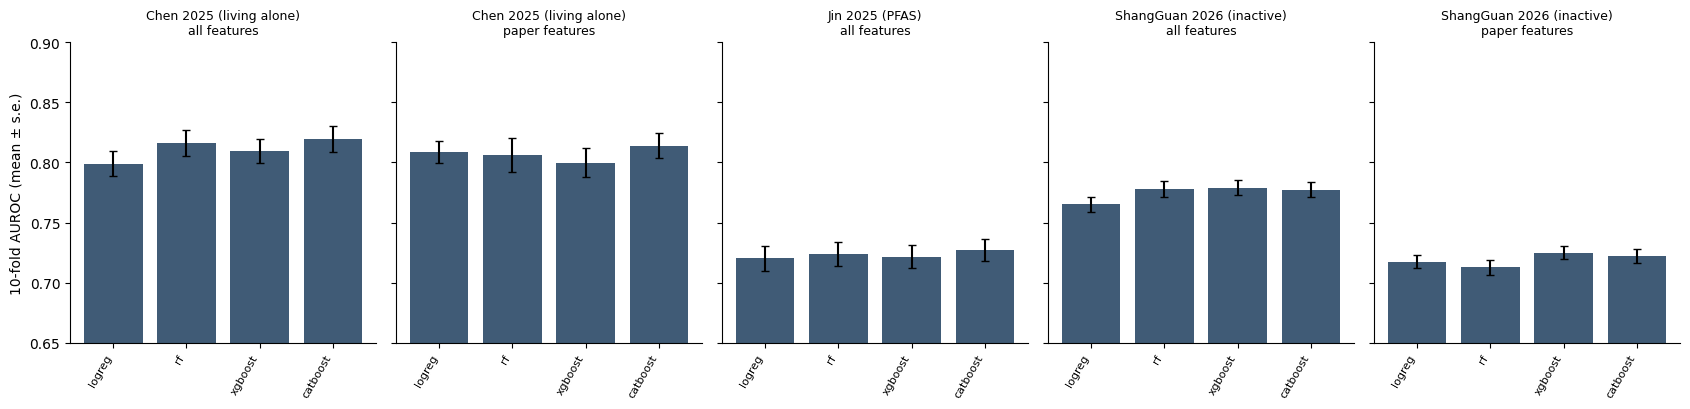

In [5]:
import matplotlib.pyplot as plt  # noqa: E402

groups = sorted({k[:2] for k in preds})
fig, axes = plt.subplots(1, len(groups), figsize=(3.4 * len(groups), 4.2), sharey=True)
for ax, (bundle, fs) in zip(np.atleast_1d(axes), groups):
    ms = [m for m in order if (bundle, fs, m) in preds]
    f = [fold_auc(preds[(bundle, fs, m)]["cv"]) for m in ms]
    colors = ["#E9783D" if m in MODELS else "#405B76" for m in ms]
    ax.bar(range(len(ms)), [x.mean() for x in f], yerr=[x.std() / np.sqrt(10) for x in f], color=colors, capsize=3)
    ax.set_xticks(range(len(ms)), ms, rotation=60, ha="right", fontsize=8)
    ax.set_title(f"{NAMES.get(bundle, bundle)}\n{fs} features", fontsize=9)
    ax.set_ylim(0.65, 0.9)
    ax.spines[["top", "right"]].set_visible(False)
np.atleast_1d(axes)[0].set_ylabel("10-fold AUROC (mean ± s.e.)")
plt.tight_layout()
plt.show()